# Customer Return-Risk Modelling

## tl;dr

Gradient Boosting produced the strongest validation PR-AUC. A campaign cutoff of 0.37 increases recall for likely returners while keeping precision above 56%. The result is a validation decision, not final test performance.

## Context & Methods

Models estimate whether a known customer will purchase during the next 90 days. Training uses earlier snapshots and validation uses a later, purged period. The final test file is not loaded.

### Selection rule

PR-AUC is primary because it assesses ranking quality for the return class. ROC-AUC, precision, recall, F1, calibration, and a simple campaign cost are secondary checks. Tuning does not guarantee improvement.

In [1]:
from pathlib import Path
import json, os, sys
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display
from src.model_evaluation import run
sns.set_theme(style='whitegrid')

## Model Run

### 1. Execute validation-only analysis

In [2]:
metadata = run(ROOT / 'reports/generated')
print(json.dumps(metadata, indent=2))
assert metadata['test_evaluated'] is False

{
  "selected_model": "gradient_boosting",
  "selection_metric": "validation_pr_auc",
  "campaign_threshold": 0.37000000000000016,
  "validation_metrics": {
    "accuracy": 0.704055619930475,
    "precision": 0.5634233316352522,
    "recall": 0.7247706422018348,
    "f1": 0.6339925480080252,
    "roc_auc": 0.784429045581147,
    "pr_auc": 0.7146227349463085
  },
  "training_return_rate": 0.4964544923667306,
  "smote_note": "Evaluated inside the training pipeline; training classes were already nearly balanced.",
  "test_evaluated": false
}


## Results

### 2. Compare baselines, class weighting, SMOTE, and ensembles

,model,accuracy,precision,recall,f1,roc_auc,pr_auc,brier_score
0,gradient_boosting,0.752,0.692,0.535,0.604,0.784,0.715,0.172
1,logistic_smote,0.754,0.666,0.607,0.636,0.788,0.709,0.176
2,logistic_class_weight,0.754,0.667,0.609,0.637,0.788,0.708,0.176
3,tuned_random_forest,0.730,0.629,0.573,0.600,0.771,0.687,0.181
4,tuned_xgboost,0.718,0.606,0.583,0.594,0.765,0.682,0.184
5,recency_heuristic,0.734,0.665,0.499,0.570,0.755,0.616,0.209
6,majority_baseline,0.646,0.000,0.000,0.000,0.500,0.354,0.249


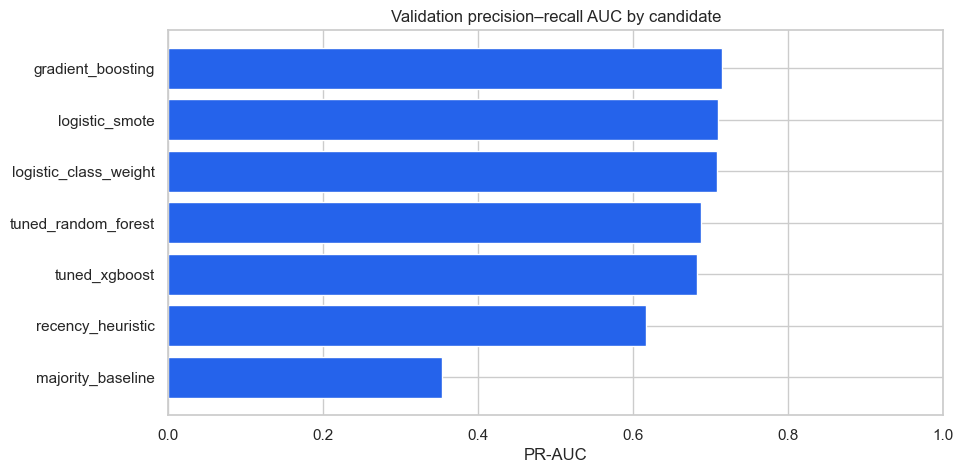

In [3]:
comparison = pd.read_csv(ROOT / 'reports/generated/classification_candidate_comparison.csv')
display(comparison.style.format({c:'{:.3f}' for c in comparison.columns if c != 'model'}))
plot = comparison.sort_values('pr_auc')
fig, ax = plt.subplots(figsize=(10,5))
ax.barh(plot['model'], plot['pr_auc'], color='#2563EB')
ax.set(title='Validation precision–recall AUC by candidate', xlabel='PR-AUC', ylabel='')
ax.set_xlim(0,1); plt.show()

SMOTE is included as a controlled comparison inside the training pipeline. Because the training target is already close to balanced, synthetic oversampling has little practical justification unless it improves later-period validation.

### 3. Review five-fold time-aware stability

In [4]:
cv = pd.read_csv(ROOT / 'reports/generated/classification_final_cv_summary.csv')
display(cv.style.format({'validation_mean':'{:.3f}','validation_std':'{:.3f}','training_mean':'{:.3f}'}))

,metric,validation_mean,validation_std,training_mean
0,pr_auc,0.773,0.045,0.860
1,roc_auc,0.777,0.019,0.821
2,f1,0.694,0.039,0.771


### 4. Review RandomizedSearch and focused GridSearch evidence

In [5]:
randomized = pd.read_csv(ROOT / 'reports/generated/classification_randomized_search.csv')
display(randomized)
print('RandomizedSearch explored broad Random Forest and XGBoost spaces using five time-ordered folds.')
print('Focused GridSearch refined the strongest cross-validation tree candidate.')
print('The tuned Random Forest was not selected because later validation performance was weaker.')

,model,cv_pr_auc,model__max_depth,model__max_features,model__min_samples_leaf,model__n_estimators,model__colsample_bytree,model__learning_rate,model__min_child_weight,model__subsample
0,random_forest,0.792952,16,0.8,4.0,506,NaN,NaN,NaN,NaN
1,xgboost,0.786813,7,NaN,NaN,198,0.885244,0.132039,9.0,0.857432


RandomizedSearch explored broad Random Forest and XGBoost spaces using five time-ordered folds.
Focused GridSearch refined the strongest cross-validation tree candidate.
The tuned Random Forest was not selected because later validation performance was weaker.


## Decision Threshold

### 5. Choose the campaign selection cutoff

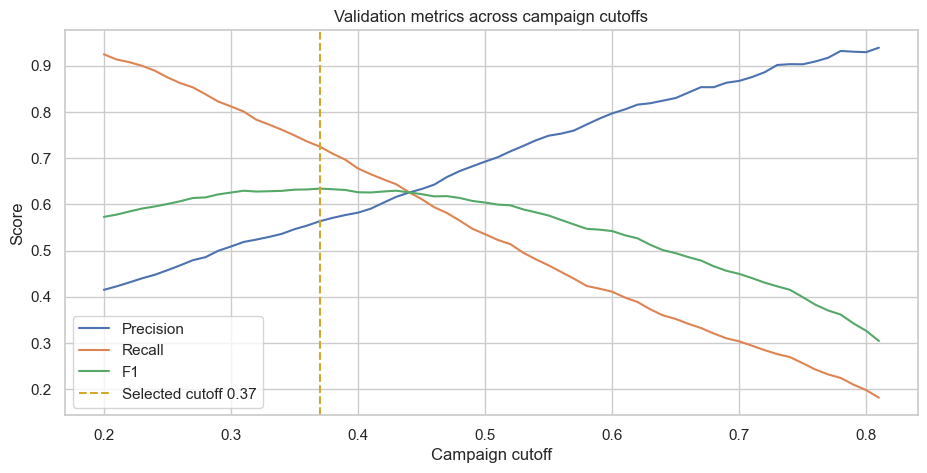

,threshold,business_cost,accuracy,precision,recall,f1,roc_auc,pr_auc
17,0.37,1697,0.704056,0.563423,0.724771,0.633993,0.784429,0.714623
18,0.38,1701,0.708459,0.570601,0.709699,0.632593,0.784429,0.714623
16,0.36,1710,0.697103,0.554021,0.735911,0.632142,0.784429,0.714623
19,0.39,1706,0.711935,0.576777,0.696592,0.631048,0.784429,0.714623
15,0.35,1716,0.691078,0.546106,0.749017,0.631666,0.784429,0.714623


In [6]:
thresholds = pd.read_csv(ROOT / 'reports/generated/classification_thresholds_final.csv')
chosen = metadata['campaign_threshold']
fig, ax = plt.subplots(figsize=(11,5))
ax.plot(thresholds['threshold'], thresholds['precision'], label='Precision')
ax.plot(thresholds['threshold'], thresholds['recall'], label='Recall')
ax.plot(thresholds['threshold'], thresholds['f1'], label='F1')
ax.axvline(chosen, color='#D4A72C', linestyle='--', label=f'Selected cutoff {chosen:.2f}')
ax.set(title='Validation metrics across campaign cutoffs', xlabel='Campaign cutoff', ylabel='Score')
ax.legend(); plt.show()
display(thresholds.loc[(thresholds['threshold']-chosen).abs().nsmallest(5).index])

The illustrative cost assigns twice as much penalty to missing a future returner as to selecting a non-returner. This is a modelling assumption, not measured campaign economics.

## Calibration

### 6. Compare predicted likelihood with observed return rate

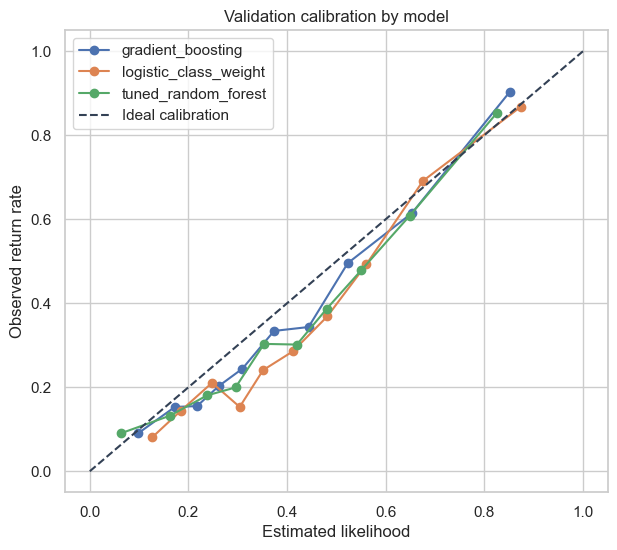

In [7]:
calibration = pd.read_csv(ROOT / 'reports/generated/classification_calibration.csv')
fig, ax = plt.subplots(figsize=(7,6))
for name, frame in calibration.groupby('model'):
    if name in ['gradient_boosting','logistic_class_weight','tuned_random_forest']:
        ax.plot(frame['predicted_probability'], frame['observed_return_rate'], marker='o', label=name)
ax.plot([0,1],[0,1], color='#334155', linestyle='--', label='Ideal calibration')
ax.set(title='Validation calibration by model', xlabel='Estimated likelihood', ylabel='Observed return rate')
ax.legend(); plt.show()

## Error Analysis

### 7. Check performance by customer recency

In [8]:
segments = pd.read_csv(ROOT / 'reports/generated/classification_segment_errors.csv')
display(segments.style.format({c:'{:.3f}' for c in segments.columns if c not in ['recency_band','snapshots']}))

,recency_band,snapshots,accuracy,precision,recall,f1,roc_auc,pr_auc
0,0–30 days,734,0.756,0.763,0.943,0.844,0.821,0.916
1,31–90 days,593,0.637,0.629,0.925,0.749,0.694,0.747
2,91–180 days,1669,0.596,0.368,0.623,0.463,0.650,0.413
3,181+ days,1319,0.842,0.387,0.060,0.103,0.622,0.224


Segment results are diagnostic, not proof that recency causes return behaviour. Small or unstable bands should not receive separate operational thresholds without further validation.

## Explainability

### 8. Factors associated with predictions

,feature,mean_absolute_shap
0,orders_per_30_days,0.360473
1,tenure_days,0.211318
2,revenue_180d,0.199206
3,recency_days,0.157276
4,orders_180d,0.125257
5,order_value_std,0.101752
6,revenue_lifetime,0.096532
7,products_lifetime,0.086408
8,historical_return_value_rate,0.083091
9,orders_lifetime,0.071165


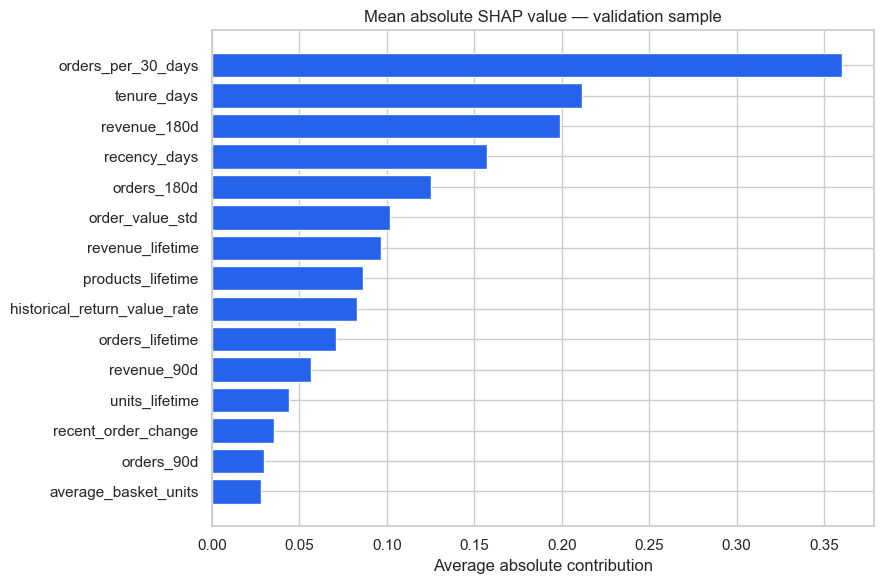

In [9]:
shap_importance = pd.read_csv(ROOT / 'reports/generated/classification_shap_importance.csv').head(15)
display(shap_importance)
fig, ax = plt.subplots(figsize=(9,6))
ranked = shap_importance.sort_values('mean_absolute_shap')
ax.barh(ranked['feature'], ranked['mean_absolute_shap'], color='#2563EB')
ax.set(title='Mean absolute SHAP value — validation sample', xlabel='Average absolute contribution', ylabel='')
plt.tight_layout(); plt.show()

SHAP describes how the fitted model uses variables; it does not show that changing a variable would cause a customer to return.

### 9. Inspect simplified Decision Tree and Random Forest structures

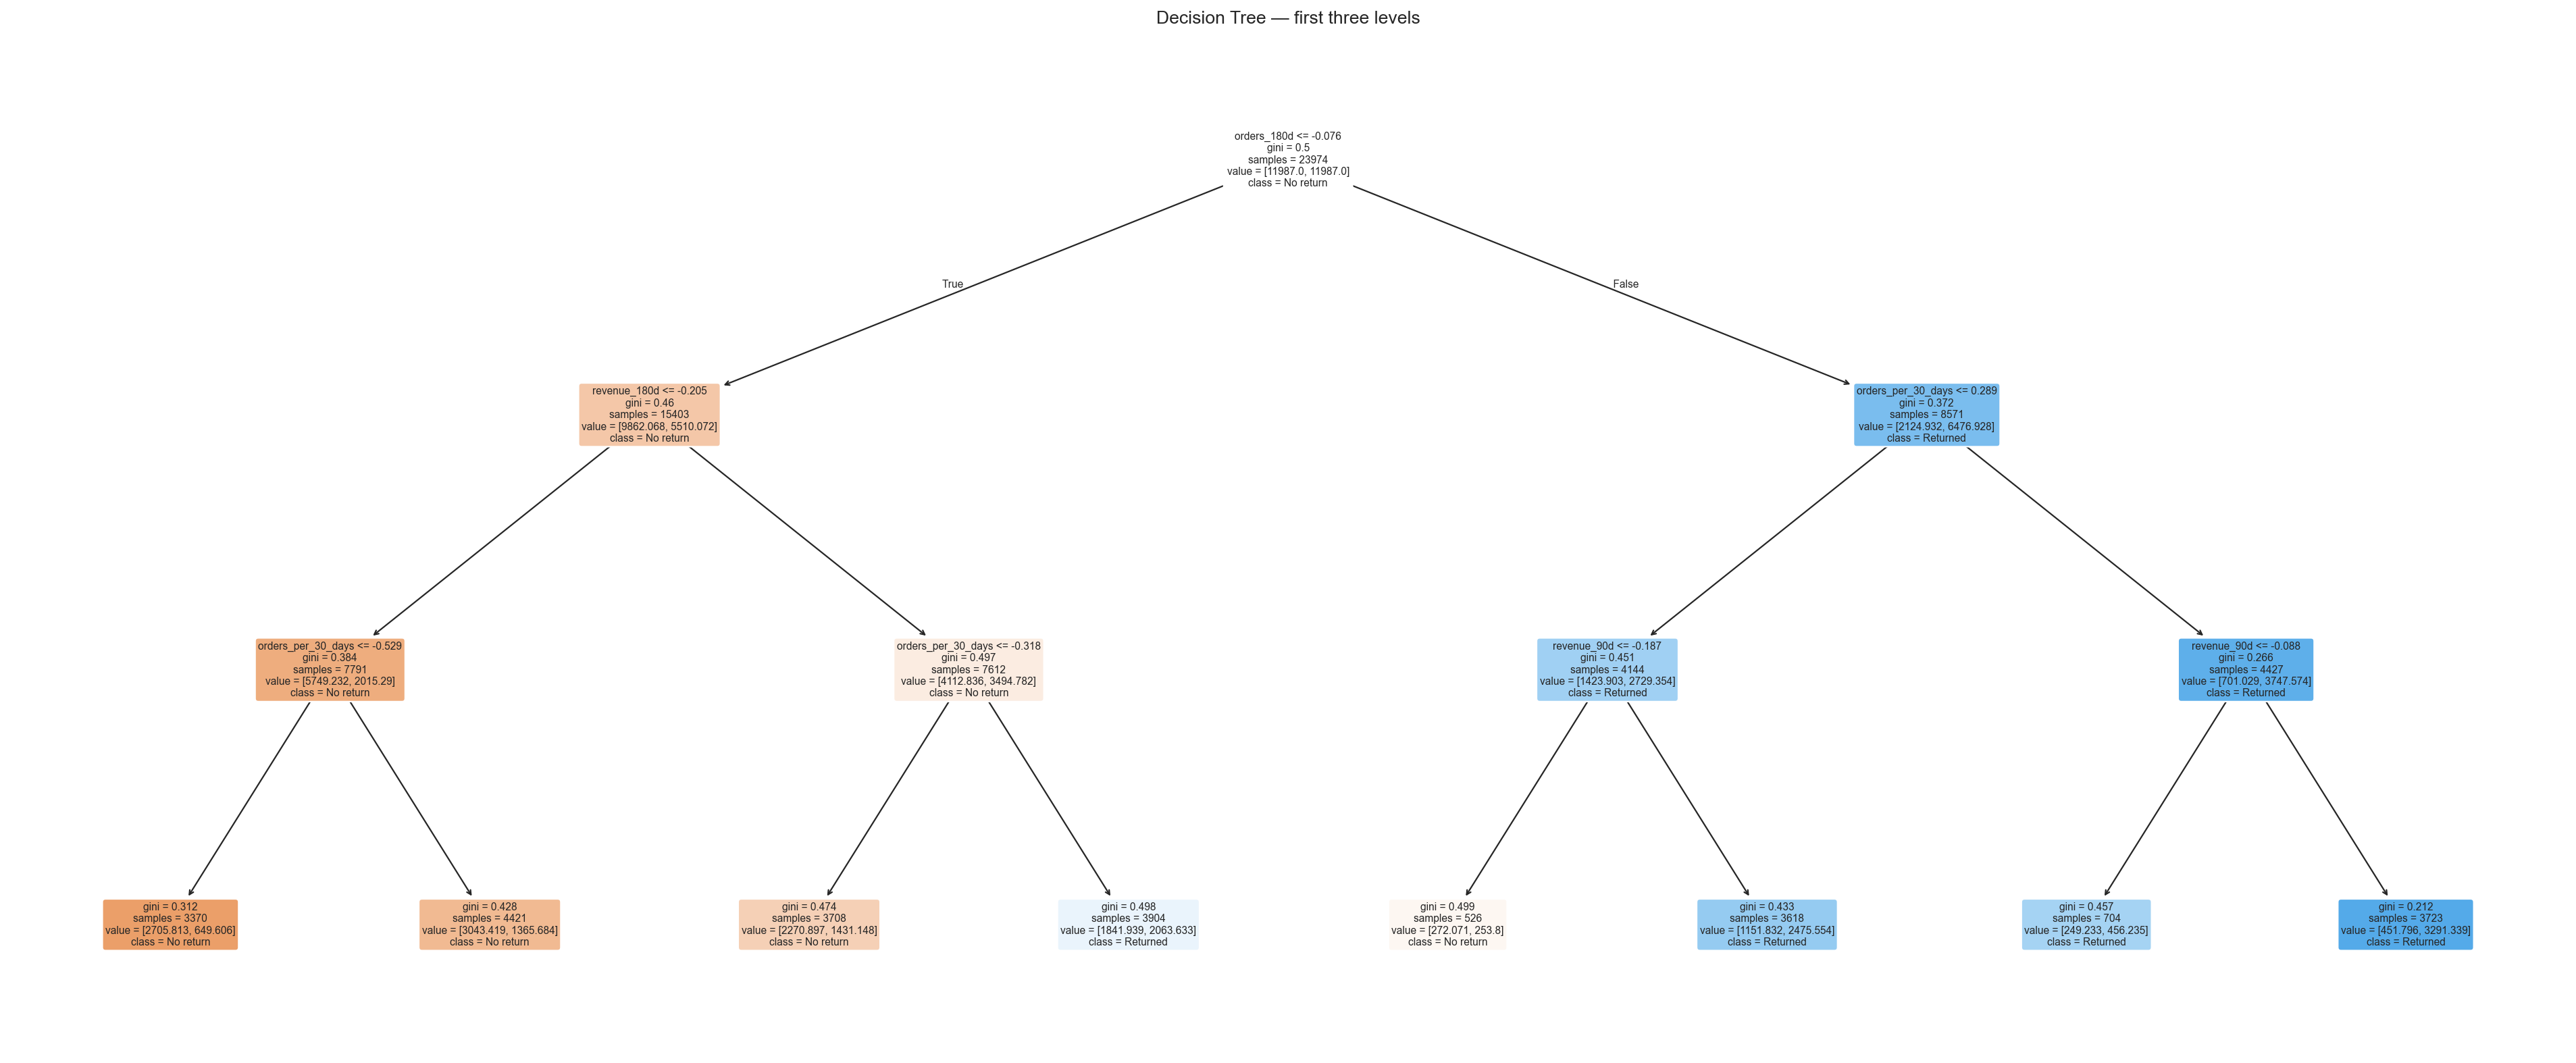

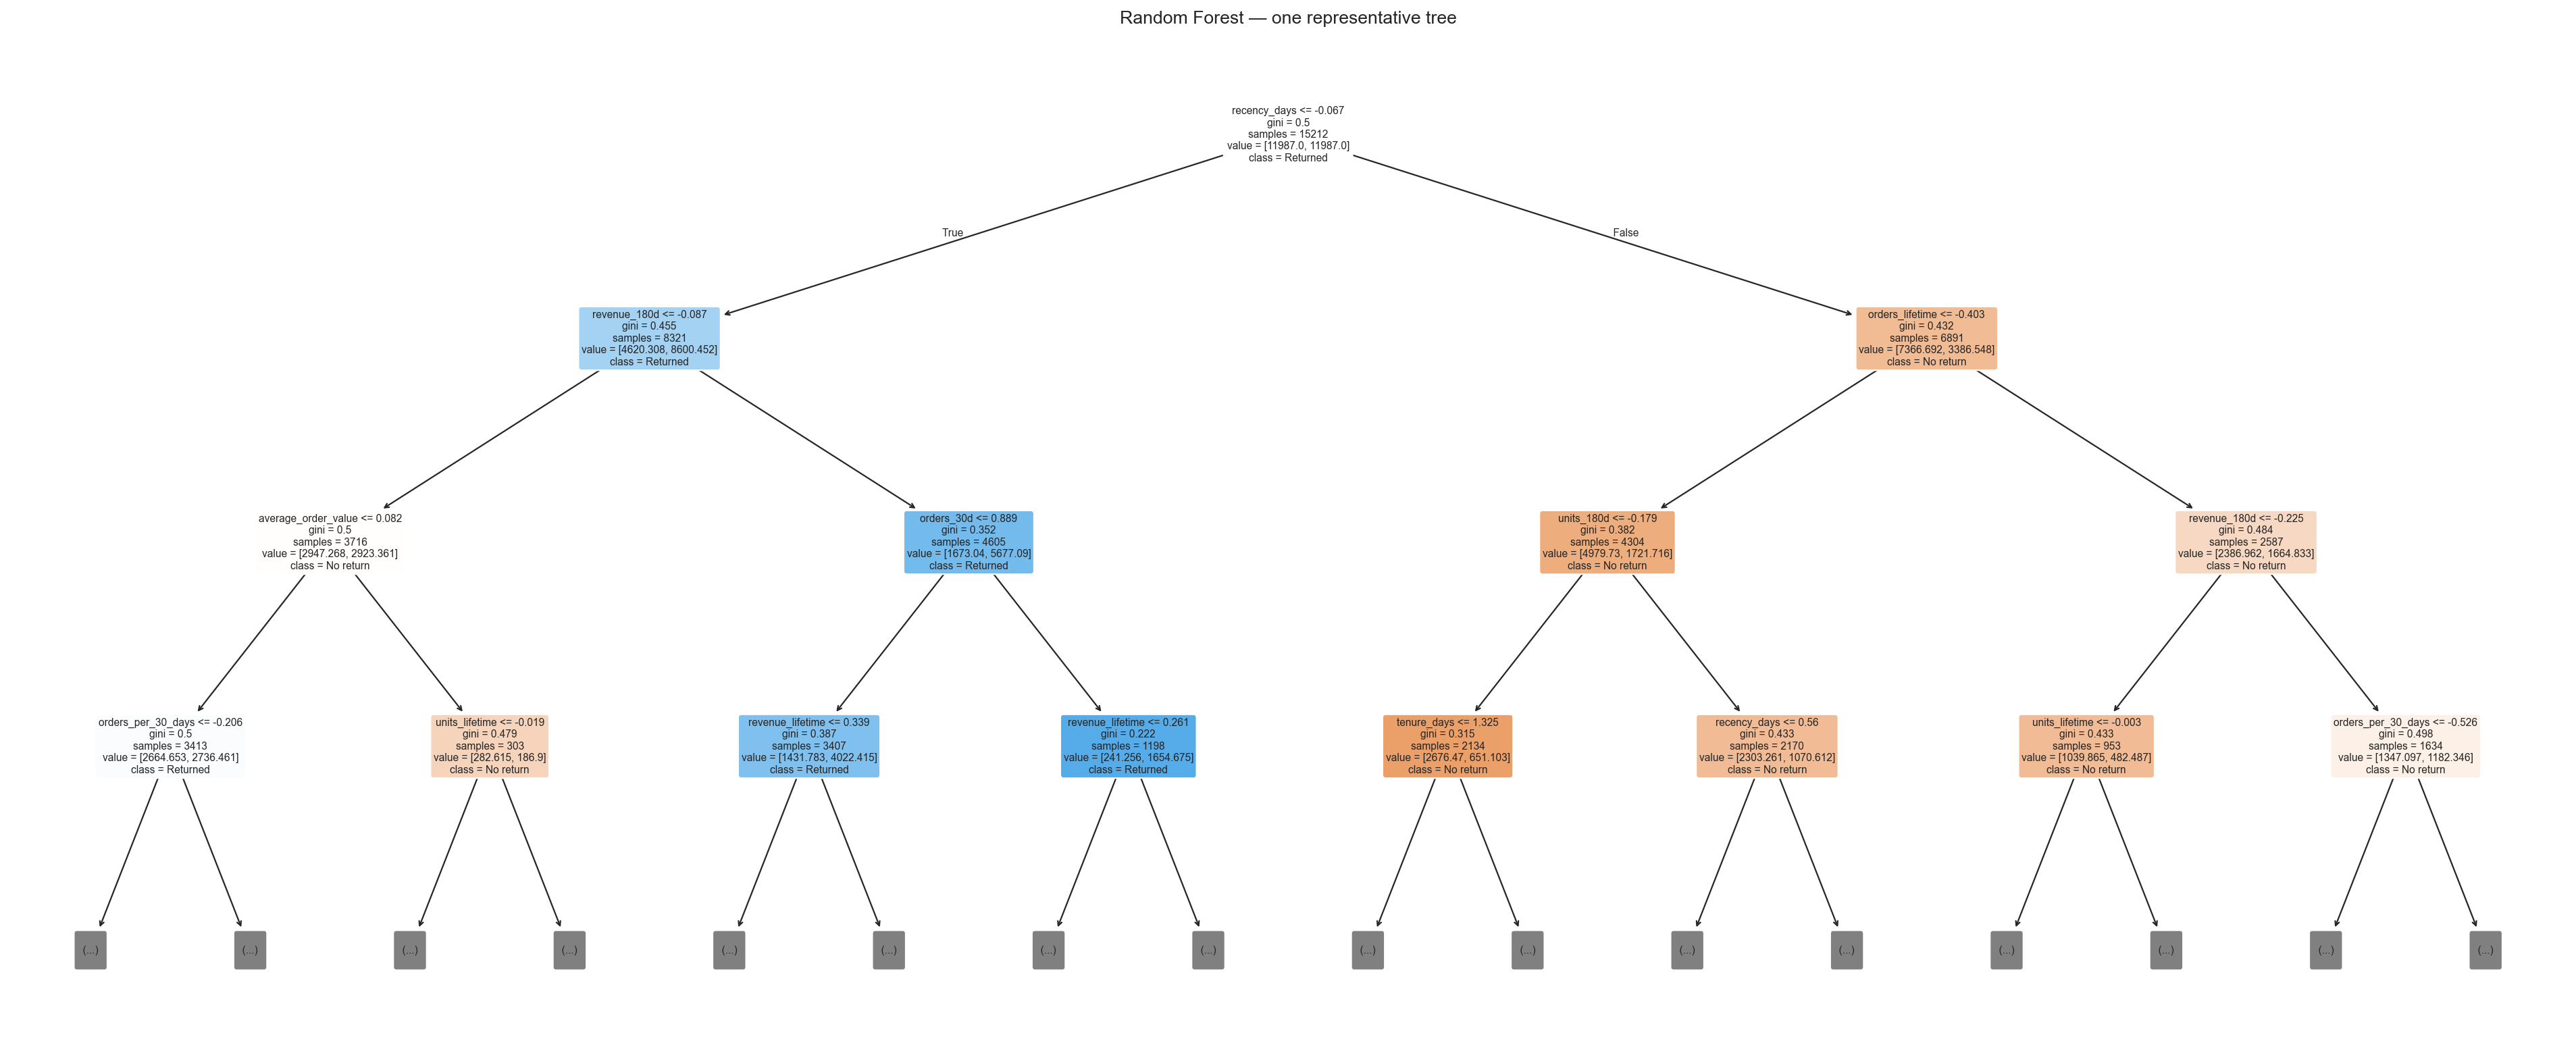

In [10]:
display(Image(filename=str(ROOT / 'reports/figures/decision_tree_structure.png'), width=1100))
display(Image(filename=str(ROOT / 'reports/figures/random_forest_example_tree.png'), width=1100))

The Random Forest image shows one representative tree, not the complete ensemble. The ensemble prediction averages many trees and cannot be summarized by this tree alone.

## Takeaways

- Gradient Boosting is selected using later-period validation PR-AUC.
- Logistic Regression remains a competitive, more interpretable benchmark.
- SMOTE did not receive preference because the training classes are already nearly balanced.
- Tuned models were allowed to lose; tuning was not treated as automatic improvement.
- The 0.37 cutoff is tied to an explicit but illustrative campaign-cost assumption.
- Calibration, recency-band errors, and SHAP are reviewed before final testing.
- No final-test metric appears in this notebook.